<img src="../assets/ga-logo.png" style="float: left; margin: 20px; height: 55px">

# DBSCAN, Hierarchical and Other Clustering Techniques - Solution

---

### About
Understand and use DBSCAN and agglomerative (hierarchical) clustering, then compare them with k-means and three other popular algorithms (Affinity Propagation, Mean Shift and Spectral Clustering) on datasets chosen to show each one's strengths and weaknesses.

### Learning Objectives
- Describe the effect of `eps` and `min_samples` on DBSCAN, and choose `eps` with a k-distance plot.
- Identify advantages and disadvantages of DBSCAN.
- Describe agglomerative clustering, read a dendrogram, and explain how the **linkage** changes the result.
- Explain in one sentence how Affinity Propagation, Mean Shift and Spectral Clustering work.
- Compare clustering algorithms fairly, with metrics **and** pictures, and choose one for a problem.

### Notebook Guide
| Part | Topic |
|---|---|
| 1 | Data: wheat seeds (from the k-means lesson) |
| 2 | DBSCAN in depth |
| 3 | Agglomerative (hierarchical) clustering |
| 4 | Three more algorithms: Affinity Propagation, Mean Shift, Spectral Clustering |
| 5 | Head-to-head: 7 algorithms on 4 datasets |
| 6 | Choosing a clustering algorithm |


# Setup

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import (KMeans, DBSCAN, AgglomerativeClustering, AffinityPropagation, MeanShift,
                             SpectralClustering, estimate_bandwidth)
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score, pairwise_distances
from sklearn.datasets import make_blobs, make_moons
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)

# Spectral Clustering warns "Graph is not fully connected" when clusters are so well separated that no
# neighbour links join them. That's expected (and is exactly what lets it separate them), so we hide it.
import warnings
warnings.filterwarnings('ignore', message='Graph is not fully connected')

Two helpers we'll use throughout:
- `plot_clusters` colours points by cluster and draws DBSCAN's **noise points (label −1) in grey**;
- `silhouette_no_noise` computes the silhouette score on the clustered points only, because noise isn't a cluster.

In [2]:
def plot_clusters(X, labels, ax=None, title=''):
    ax = ax or plt.gca()
    X = np.asarray(X); labels = np.asarray(labels)
    noise = labels == -1
    ax.scatter(X[~noise, 0], X[~noise, 1], c=labels[~noise], cmap='tab10', s=14, vmin=0, vmax=9)
    ax.scatter(X[noise, 0], X[noise, 1], c='lightgrey', s=14, marker='x', label='noise' if noise.any() else None)
    ax.set_title(title, fontsize=10)
    if noise.any(): ax.legend(loc='lower right', fontsize=8)

def silhouette_no_noise(Z, labels):
    labels = np.asarray(labels); keep = labels != -1
    return silhouette_score(Z[keep], labels[keep]) if len(set(labels[keep])) > 1 else np.nan

# Part 1: Data: wheat seeds
---
Seven measurements of 210 wheat kernels from three varieties (the k-means lesson used the same data). The raw file is space-separated with no header.

In [3]:
names = ['area', 'perimeter', 'compactness', 'kern_len', 'kern_width', 'asymmetry', 'groove_len', 'variety']
seeds = pd.read_csv('../data/seeds_dataset.txt', sep=r'\s+', names=names)    # \s+ handles the file's double tabs
seeds.head()

,area,perimeter,compactness,kern_len,kern_width,asymmetry,groove_len,variety
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


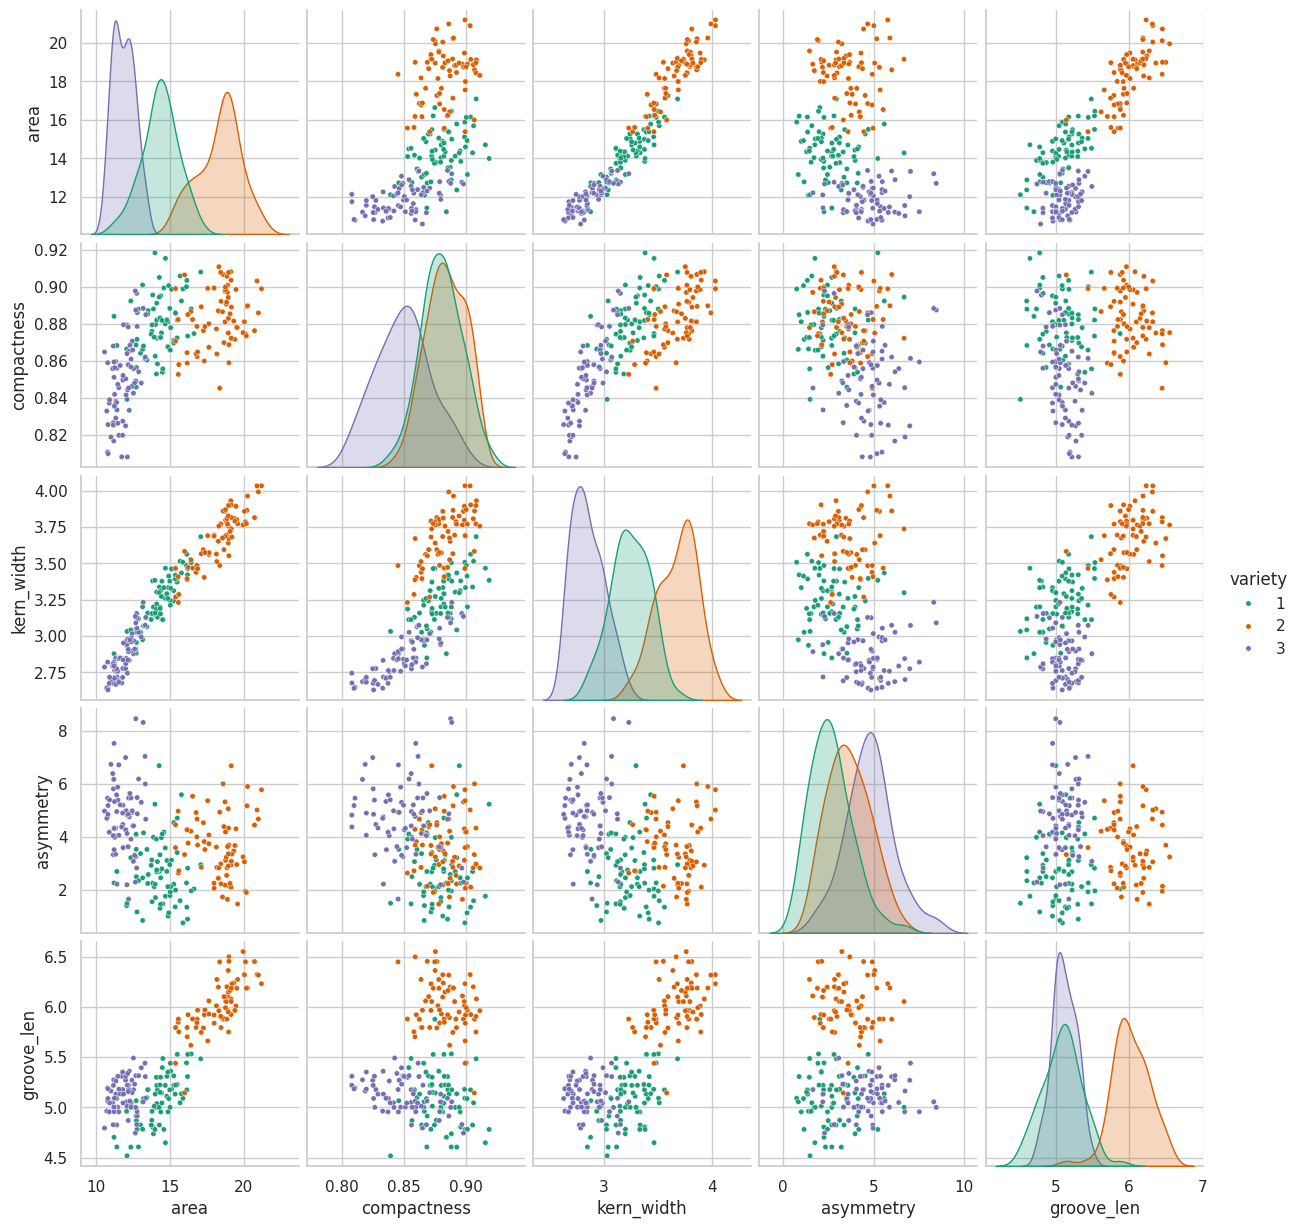

In [4]:
# Some fast EDA: which pairs of features separate the varieties?
sns.pairplot(seeds[['area', 'compactness', 'kern_width', 'asymmetry', 'groove_len', 'variety']],
             hue='variety', palette='Dark2', plot_kws={'s': 15});

To keep things visual we'll cluster on just **kernel width** and **groove length**, standardised. We keep `variety` aside: clustering never sees it, but we can use it afterwards to check how well each algorithm did, with the **adjusted Rand index (ARI)**: 1 = perfect agreement with the true groups, 0 = no better than chance.

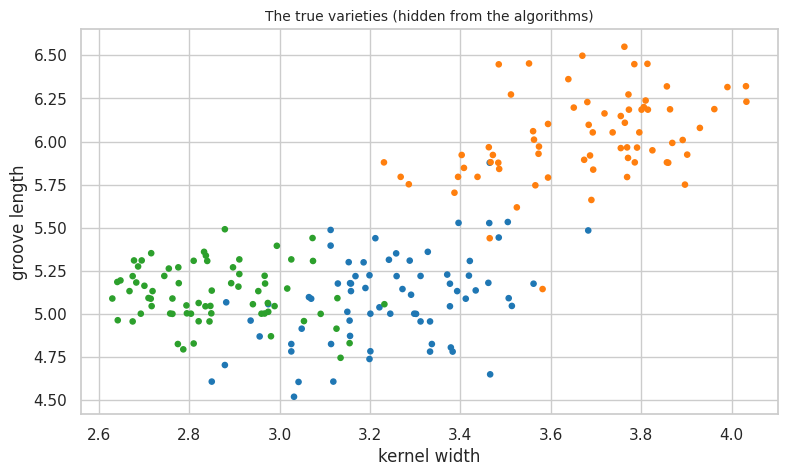

In [5]:
X = seeds[['kern_width', 'groove_len']]
Z = StandardScaler().fit_transform(X)
y_true = seeds['variety']

plot_clusters(X, y_true - 1, title='The true varieties (hidden from the algorithms)')
plt.xlabel('kernel width'); plt.ylabel('groove length');

# Part 2: DBSCAN in depth
---
**DBSCAN** (Density-Based Spatial Clustering of Applications with Noise) grows clusters from dense regions:
- a **core point** has at least `min_samples` points (including itself) within distance `eps`;
- **eps** is `epsilon`, the "searching" distance when building a cluster.
- clusters grow by linking core points that are within `eps` of each other;
- **border points** are within `eps` of a core point but aren't core themselves;
- everything else is **noise** (label −1).

It finds the number of clusters by itself, handles any shape, and flags outliers, but it needs two settings.

In [6]:
# DBSCAN with eps = 0.3 and min_samples = 7
db = DBSCAN(eps=0.3, min_samples=7).fit(Z)
labels = db.labels_
print('clusters found:', len(set(labels) - {-1}), '| noise points:', (labels == -1).sum())

clusters found: 2 | noise points: 28


### Core, border and noise points

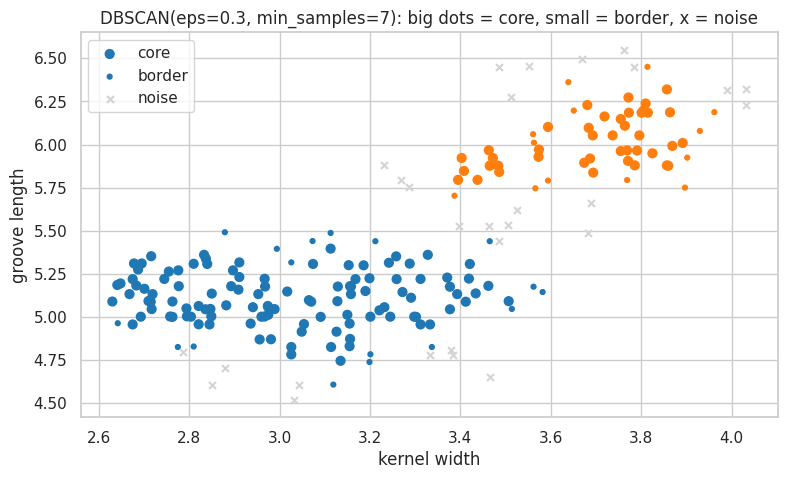

In [7]:
core = np.zeros(len(labels), dtype=bool); core[db.core_sample_indices_] = True
Xv = X.values
plt.scatter(Xv[core, 0], Xv[core, 1], c=labels[core], cmap='tab10', vmin=0, vmax=9, s=40, label='core')
border = ~core & (labels != -1)
plt.scatter(Xv[border, 0], Xv[border, 1], c=labels[border], cmap='tab10', vmin=0, vmax=9, s=12, label='border')
plt.scatter(Xv[labels == -1, 0], Xv[labels == -1, 1], c='lightgrey', marker='x', s=25, label='noise')
plt.xlabel('kernel width'); plt.ylabel('groove length'); plt.legend()
plt.title('DBSCAN(eps=0.3, min_samples=7): big dots = core, small = border, x = noise');

## Model evaluation: silhouette score (and its noise trap)
$$s_i = \frac{b_i - a_i}{\max(a_i, b_i)}$$
- $a_i$ (**cohesion**) = average distance from point $i$ to the other points in its own cluster;
- $b_i$ (**separation**) = average distance from point $i$ to the points in the nearest other cluster.

**Trap:** `silhouette_score(Z, db.labels_)` treats the noise label −1 as if it were a cluster. Noise points are scattered, so this "cluster" drags the score around. Score the clustered points only:

In [8]:
print(f'silhouette counting noise as a cluster: {silhouette_score(Z, labels):.3f}   <- what the original notebook did')
print(f'silhouette on clustered points only:    {silhouette_no_noise(Z, labels):.3f}')
print(f'ARI vs the true varieties:              {adjusted_rand_score(y_true, labels):.3f}')

silhouette counting noise as a cluster: 0.433   <- what the original notebook did
silhouette on clustered points only:    0.656
ARI vs the true varieties:              0.421


## The effect of `eps` and `min_samples`
Small changes make a big difference: too small an `eps` and everything is noise; too large and everything merges.

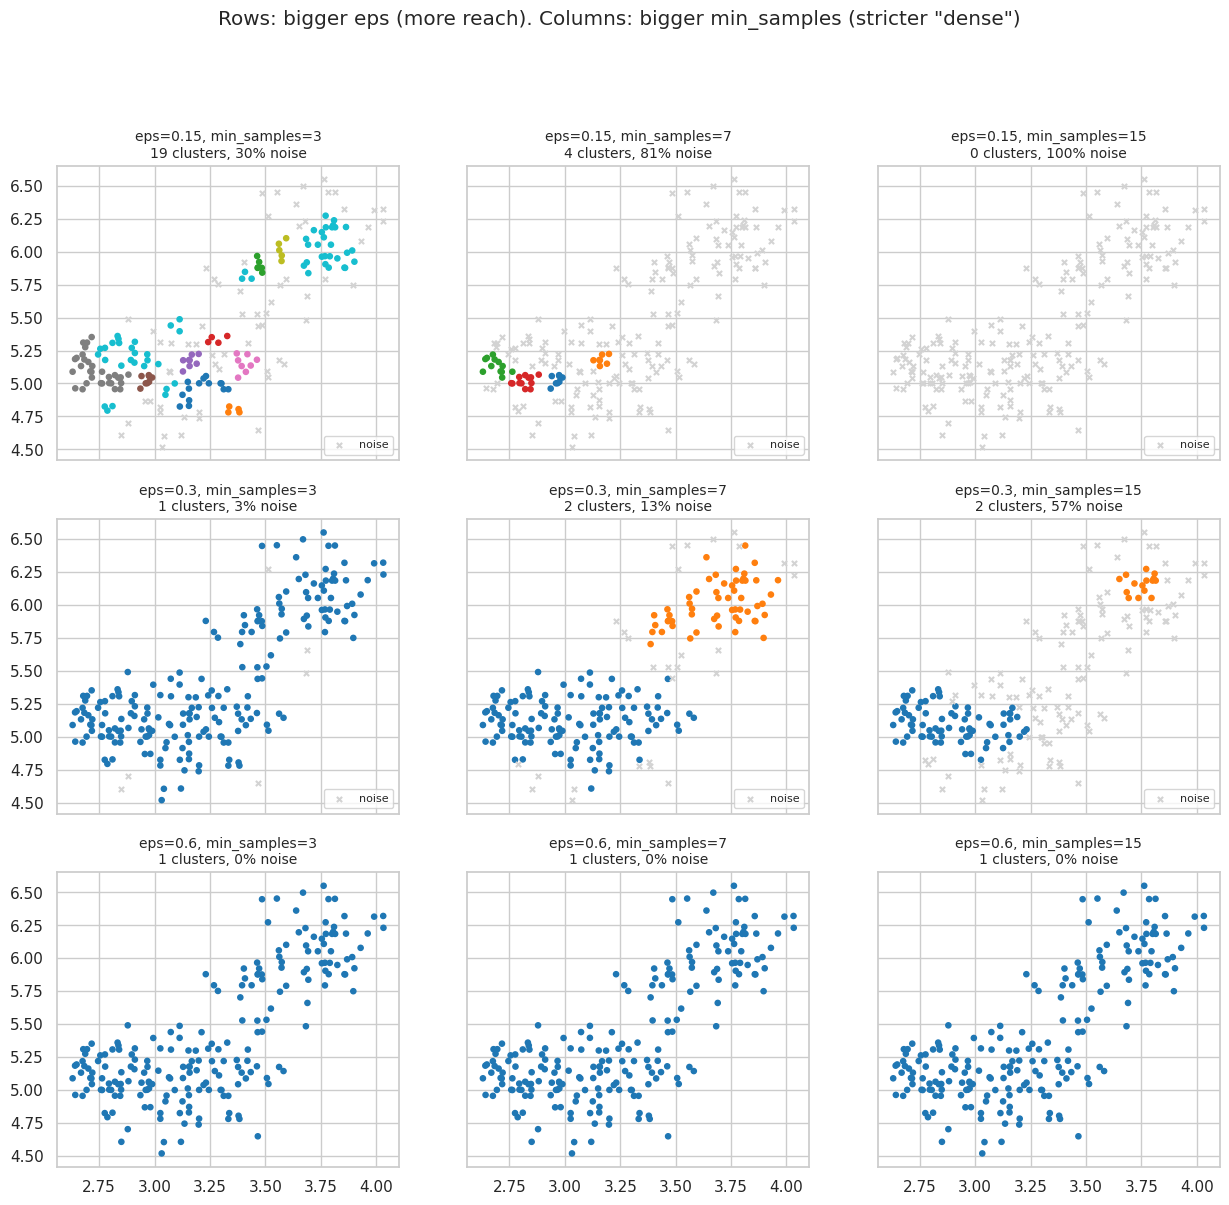

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(15, 13), sharex=True, sharey=True)
for row, eps in zip(axes, [0.15, 0.3, 0.6]):
    for ax, m in zip(row, [3, 7, 15]):
        lab = DBSCAN(eps=eps, min_samples=m).fit_predict(Z)
        plot_clusters(X, lab, ax, f'eps={eps}, min_samples={m}\n{len(set(lab) - {-1})} clusters, {(lab == -1).mean():.0%} noise')
plt.suptitle('Rows: bigger eps (more reach). Columns: bigger min_samples (stricter "dense")', y=1.0);

## Choosing `eps`: the k-distance plot
For every point, find the distance to its k-th nearest neighbour (k = `min_samples`), sort the distances and plot them. Points inside clusters have small distances; outliers have large ones. A good `eps` is at the **knee**, where the curve bends upwards.

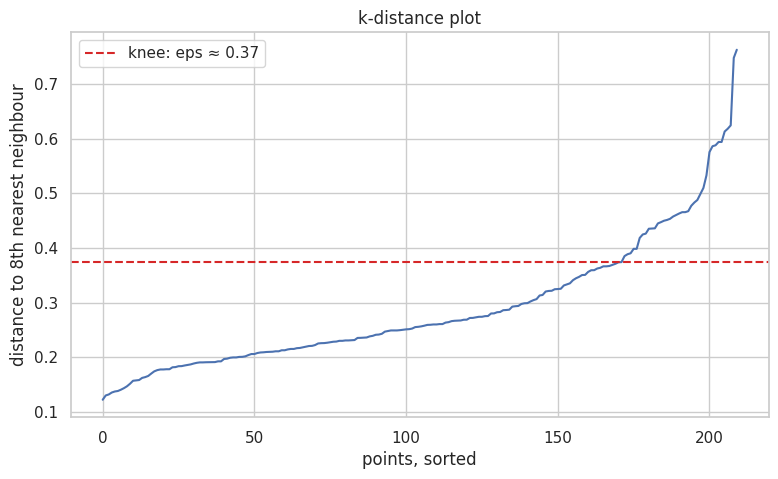

In [10]:
def knee_eps(Z, k):
    dist = np.sort(NearestNeighbors(n_neighbors=k).fit(Z).kneighbors(Z)[0][:, -1])
    x = np.linspace(0, 1, len(dist)); yv = (dist - dist.min()) / (dist.max() - dist.min())
    return dist, dist[np.argmax(x - yv)]           # knee = furthest point below the straight line between the ends

dist, eps_knee = knee_eps(Z, k=8)
plt.plot(dist); plt.axhline(eps_knee, color='tab:red', ls='--', label=f'knee: eps ≈ {eps_knee:.2f}')
plt.xlabel('points, sorted'); plt.ylabel('distance to 8th nearest neighbour'); plt.legend()
plt.title('k-distance plot');

In [11]:
db_knee = DBSCAN(eps=eps_knee, min_samples=8).fit(Z)
print(f'eps={eps_knee:.2f}: {len(set(db_knee.labels_) - {-1})} clusters, {(db_knee.labels_ == -1).mean():.0%} noise, '
      f'silhouette {silhouette_no_noise(Z, db_knee.labels_):.3f}, ARI {adjusted_rand_score(y_true, db_knee.labels_):.3f}')

eps=0.37: 2 clusters, 7% noise, silhouette 0.636, ARI 0.466


## Brute force: what does "best" mean?
The original notebook searched hundreds of `eps`/`min_samples` combinations and picked the highest silhouette. Because we happen to know the true varieties, we can check whether the silhouette's favourite is actually a good clustering.

In [12]:
res = []
for e in np.linspace(0.1, 0.8, 36):
    for n in range(3, 16):
        lab = DBSCAN(eps=e, min_samples=n).fit_predict(Z)
        if len(set(lab) - {-1}) < 2: continue
        res.append({'eps': round(e, 2), 'min_samples': n, 'silhouette': silhouette_no_noise(Z, lab),
                    'ARI': adjusted_rand_score(y_true, lab), 'clusters': len(set(lab) - {-1}), 'noise': (lab == -1).mean()})
df_res = pd.DataFrame(res)
best_sil = df_res.loc[df_res['silhouette'].idxmax()]
best_ari = df_res.loc[df_res['ARI'].idxmax()]
pd.DataFrame({'best by silhouette': best_sil, 'best by ARI (needs true labels)': best_ari}).round(3)

,best by silhouette,best by ARI (needs true labels)
eps,0.260,0.540
min_samples,14.000,13.000
silhouette,0.873,0.615
ARI,0.164,0.521
clusters,2.000,2.000
noise,0.710,0.000


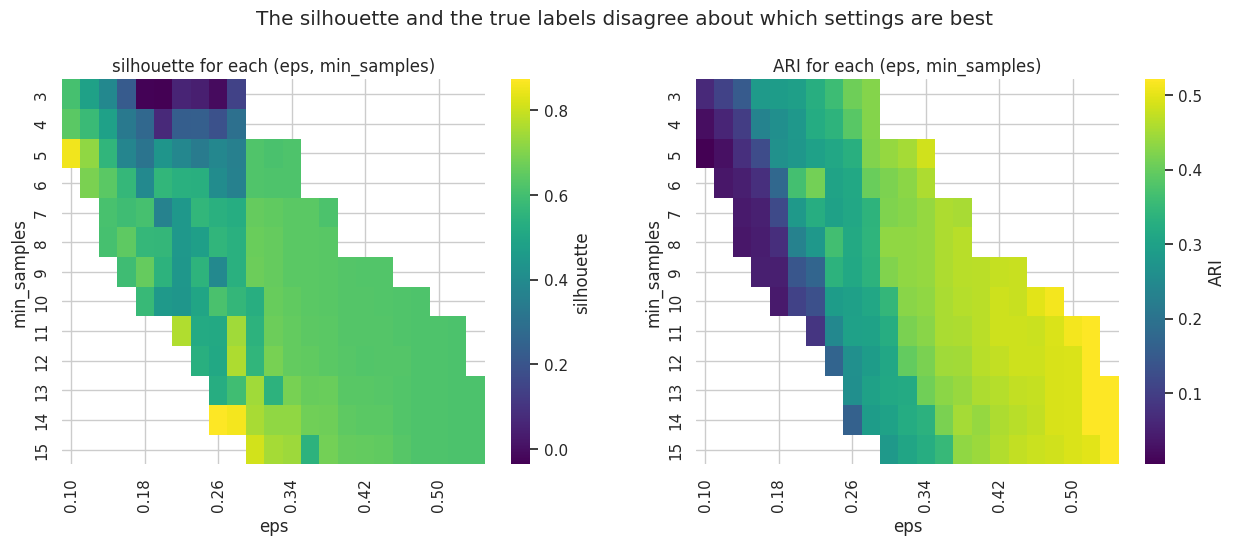

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, metric in zip(axes, ['silhouette', 'ARI']):
    grid = df_res.pivot_table(index='min_samples', columns='eps', values=metric)
    sns.heatmap(grid, ax=ax, cmap='viridis', cbar_kws={'label': metric})
    ax.set_title(f'{metric} for each (eps, min_samples)')
    ax.set_xticks(ax.get_xticks()[::4]); ax.set_xticklabels([f'{grid.columns[int(t)]:.2f}' for t in ax.get_xticks()])
plt.suptitle('The silhouette and the true labels disagree about which settings are best', y=1.02);

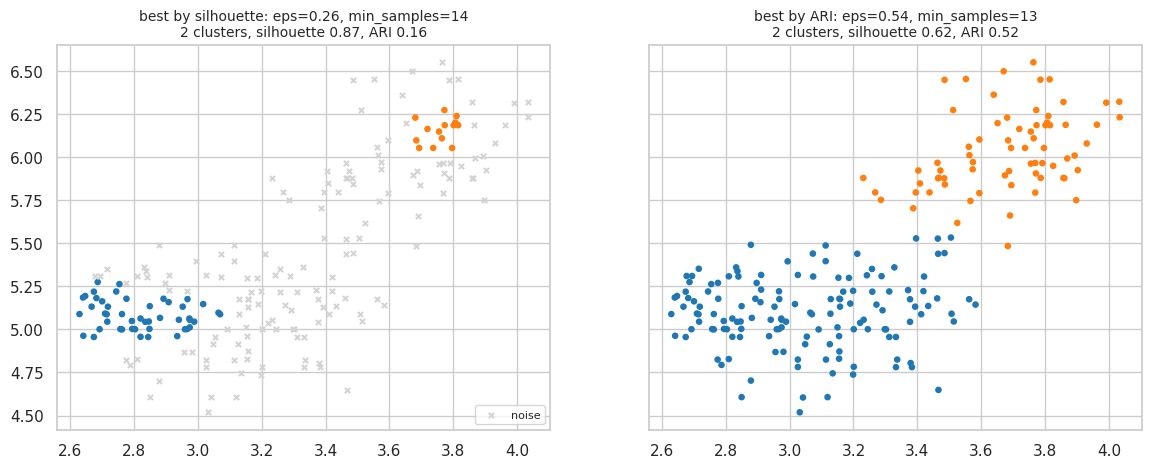

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (name, row) in zip(axes, [('silhouette', best_sil), ('ARI', best_ari)]):
    lab = DBSCAN(eps=row['eps'], min_samples=int(row['min_samples'])).fit_predict(Z)
    plot_clusters(X, lab, ax, f'best by {name}: eps={row["eps"]}, min_samples={int(row["min_samples"])}\n'
                              f'{int(row["clusters"])} clusters, silhouette {row["silhouette"]:.2f}, ARI {row["ARI"]:.2f}')

**Lesson:** the silhouette rewards a few tight, well-separated clusters, so it happily labels the awkward in-between kernels as noise. That's tidy, but it isn't the three varieties. In real projects you won't have true labels, so combine metrics with **plots** and **domain knowledge**.

---

To the slides!

---

# Part 3: Agglomerative (hierarchical) clustering
---
**Hierarchical clustering** builds a tree of clusters. The **agglomerative** (bottom-up) version, which scikit-learn implements, starts with every point as its own cluster and repeatedly **merges the two closest clusters**. "Closest" depends on the **linkage**:

| Linkage | Distance between two clusters | Tends to give |
|---|---|---|
| `ward` (default) | the increase in within-cluster variance if merged | compact, similar-sized clusters (like k-means) |
| `complete` | the **farthest** pair of points | compact clusters |
| `average` | the average distance between all pairs | a compromise |
| `single` | the **closest** pair of points | long, chained clusters (good for odd shapes, bad with noise) |

silhouette 0.439 | ARI 0.451


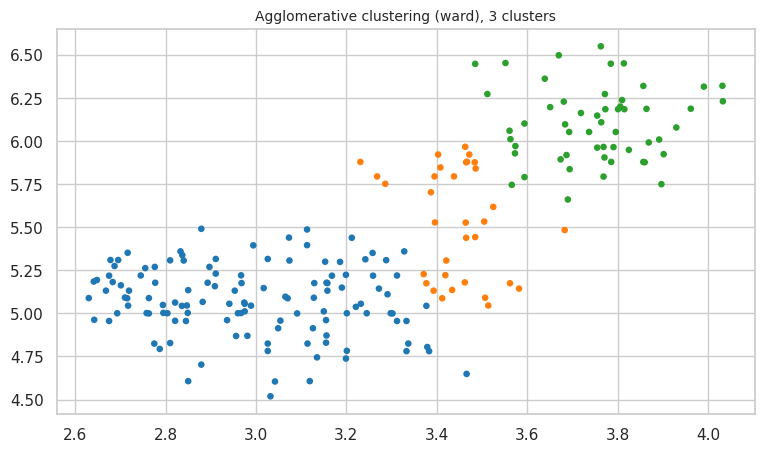

In [15]:
agglom = AgglomerativeClustering(n_clusters=3)          # ward linkage by default
agglom.fit(Z)
plot_clusters(X, agglom.labels_, title='Agglomerative clustering (ward), 3 clusters')
print(f'silhouette {silhouette_score(Z, agglom.labels_):.3f} | ARI {adjusted_rand_score(y_true, agglom.labels_):.3f}')

### The dendrogram
The dendrogram shows every merge: the height of a join is the distance at which the two clusters merged. Cutting it with a horizontal line gives a clustering. Long vertical stretches with no merges suggest natural places to cut. (We truncate it to the last 30 merges so it's readable; the original drew all 210 leaves.)

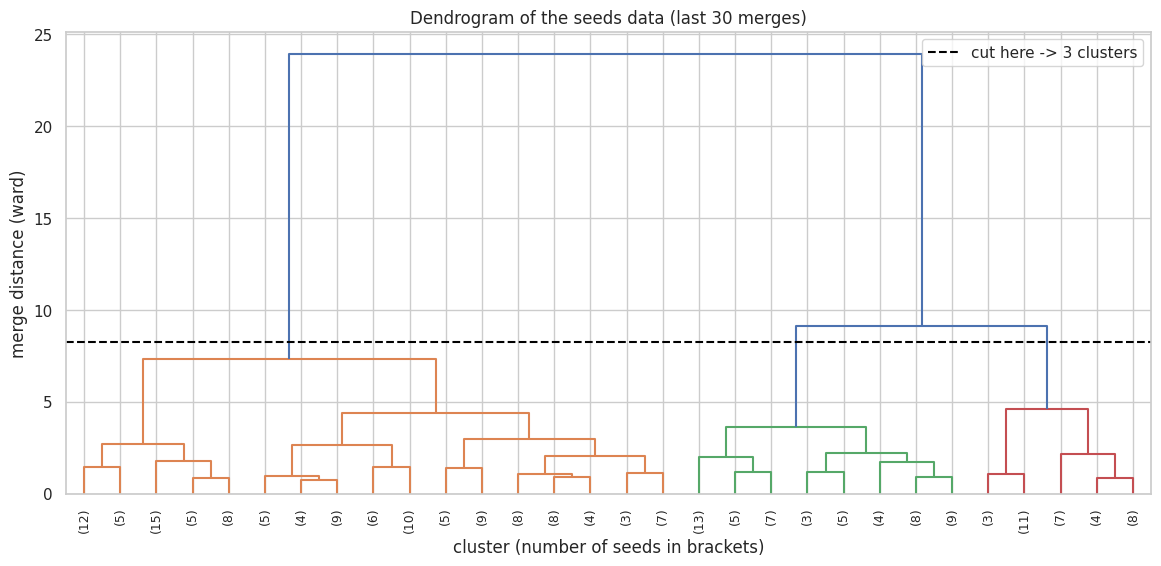

In [16]:
tree = linkage(Z, method='ward')
cut = (tree[-3, 2] + tree[-2, 2]) / 2                      # a height between the last two merges -> 3 clusters
plt.figure(figsize=(14, 6))
dendrogram(tree, truncate_mode='lastp', p=30, color_threshold=cut, leaf_rotation=90, leaf_font_size=9)
plt.axhline(cut, color='black', ls='--', label='cut here -> 3 clusters')
plt.ylabel('merge distance (ward)'); plt.xlabel('cluster (number of seeds in brackets)'); plt.legend()
plt.title('Dendrogram of the seeds data (last 30 merges)');

### Linkage matters
The same algorithm with four linkages, on the seeds and on two interlocking "moons":

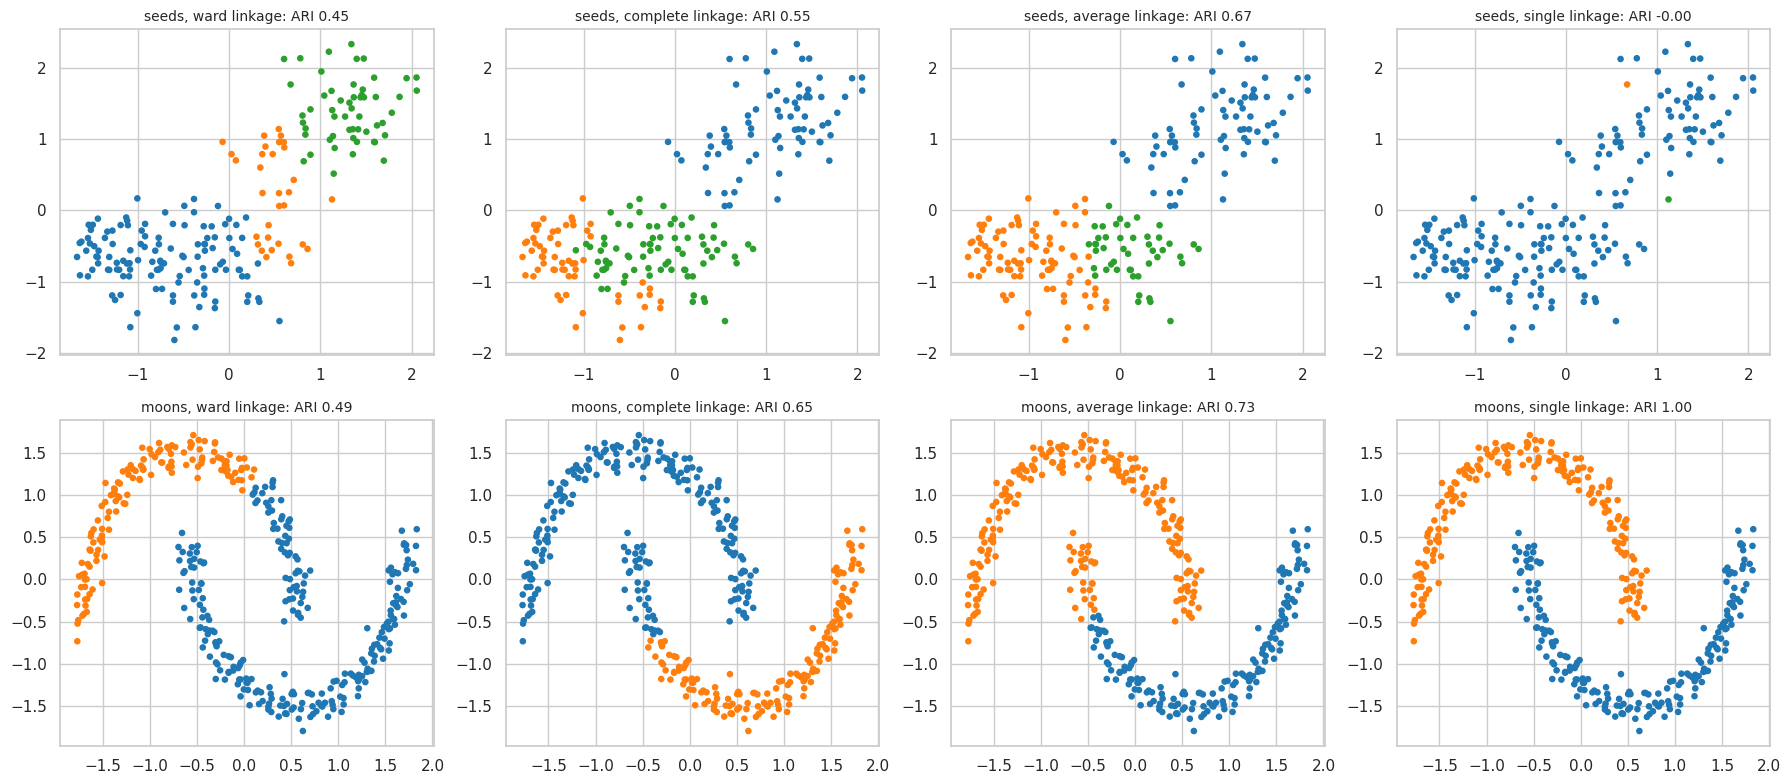

In [17]:
Xm, ym = make_moons(n_samples=400, noise=0.06, random_state=8)
Zm = StandardScaler().fit_transform(Xm)
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for row, (data, truth, k, name) in zip(axes, [(Z, y_true, 3, 'seeds'), (Zm, ym, 2, 'moons')]):
    for ax, link in zip(row, ['ward', 'complete', 'average', 'single']):
        lab = AgglomerativeClustering(n_clusters=k, linkage=link).fit_predict(data)
        plot_clusters(data, lab, ax, f'{name}, {link} linkage: ARI {adjusted_rand_score(truth, lab):.2f}')
plt.tight_layout();

On the seeds, **average** linkage does best, and **single linkage** fails completely: it chains 208 of the 210 seeds into one cluster, leaving two lone points. On the moons it's the reverse: single linkage is the only one that follows the curves perfectly. There's no universally best linkage: it depends on the shape of your data.

# Part 4: Three more algorithms
---
| Algorithm | Idea in one sentence | Needs k? | Key setting |
|---|---|---|---|
| **Affinity Propagation** | Points "vote" for exemplars by passing messages until a few representative points emerge. | No | `preference` (lower = fewer clusters), `damping` |
| **Mean Shift** | Every point climbs uphill to the nearest peak of data density; points reaching the same peak form a cluster. | No | `bandwidth` (bigger = fewer clusters) |
| **Spectral Clustering** | Builds a similarity graph of nearest neighbours, then clusters the graph's structure, so it can follow curved shapes. | Yes | `n_clusters`, `affinity` |

### Affinity Propagation: the preference controls the number of clusters
The default preference (the median similarity) usually produces **too many** clusters; the minimum similarity is a common choice for fewer.

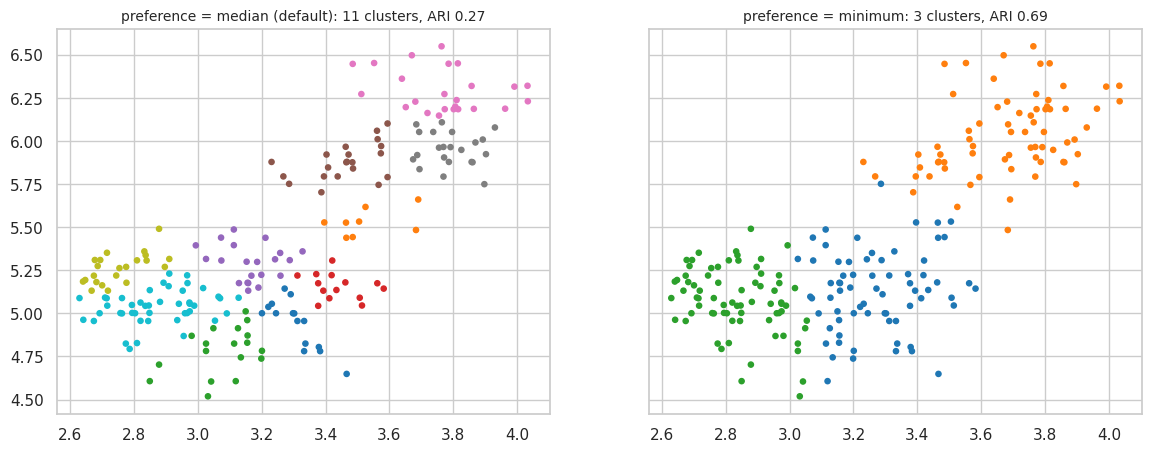

In [18]:
S = -pairwise_distances(Z, metric='sqeuclidean')        # Affinity Propagation's similarity: negative squared distance
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (name, pref) in zip(axes, [('median (default)', np.median(S)), ('minimum', np.min(S))]):
    lab = AffinityPropagation(damping=0.9, preference=pref, random_state=0).fit_predict(Z)
    plot_clusters(X, lab, ax, f'preference = {name}: {len(set(lab))} clusters, ARI {adjusted_rand_score(y_true, lab):.2f}')

### Mean Shift: the bandwidth controls the number of clusters

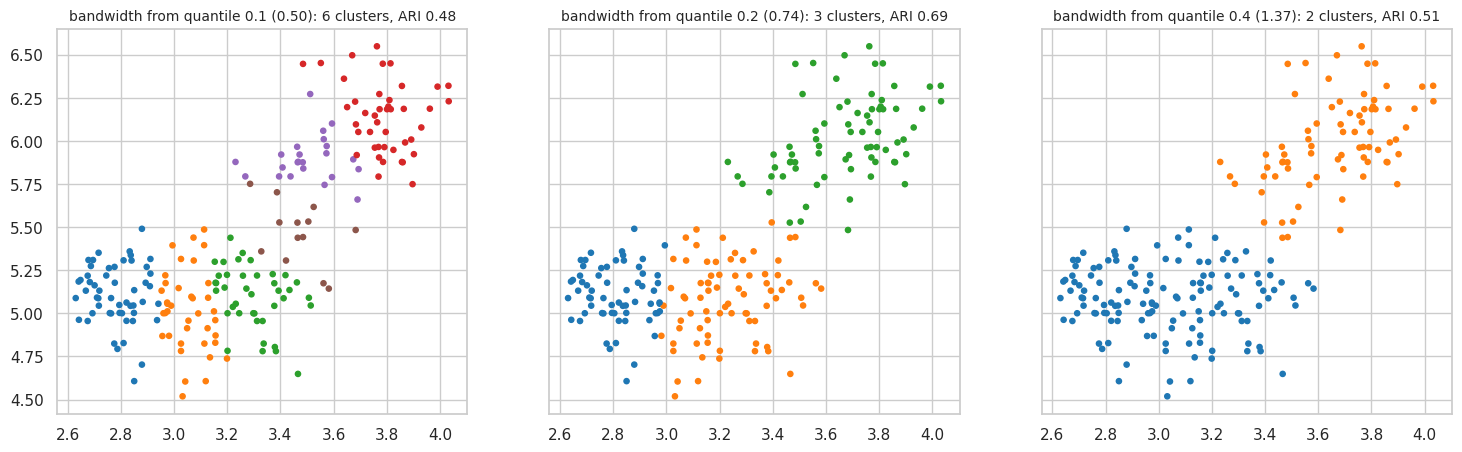

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, q in zip(axes, [0.1, 0.2, 0.4]):
    bw = estimate_bandwidth(Z, quantile=q, random_state=0)
    lab = MeanShift(bandwidth=bw, bin_seeding=True).fit_predict(Z)
    plot_clusters(X, lab, ax, f'bandwidth from quantile {q} ({bw:.2f}): {len(set(lab))} clusters, ARI {adjusted_rand_score(y_true, lab):.2f}')

### Spectral Clustering: following shapes that k-means can't

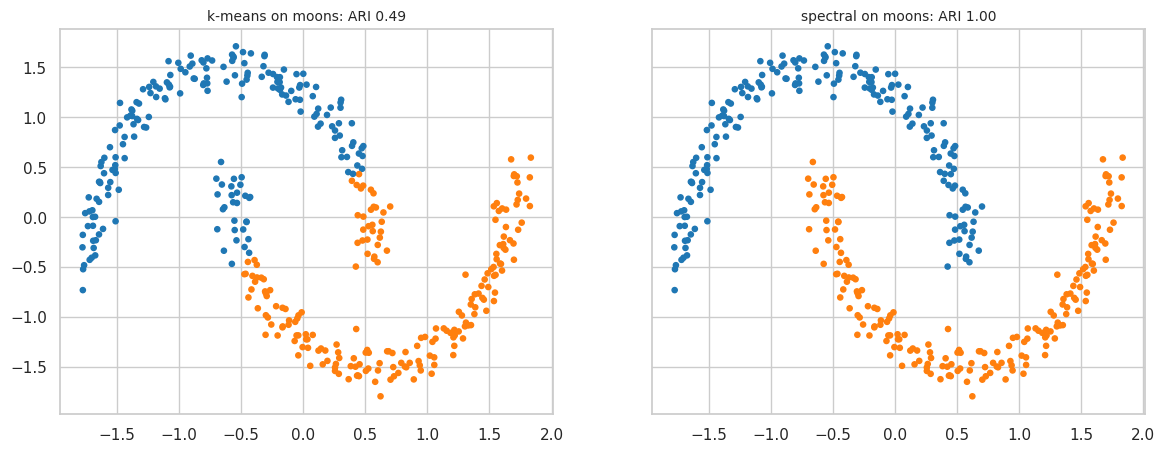

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (name, model) in zip(axes, [('k-means', KMeans(n_clusters=2, n_init=10, random_state=42)),
                                    ('spectral', SpectralClustering(n_clusters=2, affinity='nearest_neighbors', n_neighbors=10, random_state=42))]):
    lab = model.fit_predict(Zm)
    plot_clusters(Zm, lab, ax, f'{name} on moons: ARI {adjusted_rand_score(ym, lab):.2f}')

# Part 5: Head-to-head: 7 algorithms on 4 datasets
---
Four datasets, each chosen to test something different:

| Dataset | What it tests |
|---|---|
| **Blobs** | Easy, round, well-separated clusters: the "sanity check" every method should pass. |
| **Moons** | Curved, interlocking shapes: does the method assume round clusters? |
| **Mixed densities** | One big, spread-out cluster, two small tight ones, plus scattered outliers. |
| **Seeds** | Real data with overlapping groups. |

**Settings**, chosen *without* looking at the true labels (as you'd have to in a real project): the true number of clusters for the methods that need k; DBSCAN's `eps` from the k-distance knee; Mean Shift's bandwidth from `estimate_bandwidth`; Affinity Propagation with the minimum-similarity preference.

**Metrics**, the same scorecard approach as earlier lessons: ARI against the truth (higher = better), silhouette (no labels needed; noise excluded), number of clusters found, share of points labelled noise, and fit time.

In [21]:
def mixed_densities():
    Xd, yd = make_blobs(n_samples=[200, 100, 60], centers=[(0, 0), (6, 4), (6, -3)], cluster_std=[1.6, 0.4, 0.3], random_state=3)
    outliers = np.random.default_rng(0).uniform(-6, 10, (25, 2))
    return np.r_[Xd, outliers], np.r_[yd, np.full(25, -1)]          # true outliers labelled -1

datasets = {
    'Blobs': (*make_blobs(n_samples=400, centers=3, cluster_std=1.0, random_state=8), 3),
    'Moons': (*make_moons(n_samples=400, noise=0.06, random_state=8), 2),
    'Mixed densities': (*mixed_densities(), 3),
    'Seeds': (seeds[['kern_width', 'groove_len']].values, seeds['variety'].values, 3),
}

def make_algorithms(Zd, k):
    S = -pairwise_distances(Zd, metric='sqeuclidean')
    return {
        'K-Means': KMeans(n_clusters=k, n_init=10, random_state=42),
        'DBSCAN': DBSCAN(eps=knee_eps(Zd, 8)[1], min_samples=8),
        'Agglomerative (ward)': AgglomerativeClustering(n_clusters=k, linkage='ward'),
        'Hierarchical (single)': AgglomerativeClustering(n_clusters=k, linkage='single'),
        'Affinity Propagation': AffinityPropagation(damping=0.9, preference=np.min(S), random_state=0),
        'Mean Shift': MeanShift(bandwidth=estimate_bandwidth(Zd, quantile=0.2, random_state=0), bin_seeding=True),
        'Spectral': SpectralClustering(n_clusters=k, affinity='nearest_neighbors', n_neighbors=10, random_state=42),
    }

> **Naming note:** "hierarchical" and "agglomerative" clustering are the same family: scikit-learn's `AgglomerativeClustering` *is* bottom-up hierarchical clustering. We show it twice, with Ward linkage and with single linkage, because the linkage changes its behaviour so much (Part 3).

In [22]:
results, all_labels = [], {}
for dname, (Xd, yd, k) in datasets.items():
    Zd = StandardScaler().fit_transform(Xd)
    for aname, model in make_algorithms(Zd, k).items():
        start = time.time(); lab = model.fit_predict(Zd); seconds = time.time() - start
        all_labels[(dname, aname)] = (Zd, lab)
        results.append({'dataset': dname, 'algorithm': aname, 'ARI': adjusted_rand_score(yd, lab),
                        'silhouette': silhouette_no_noise(Zd, lab), 'clusters found': len(set(lab) - {-1}),
                        'noise %': (lab == -1).mean() * 100, 'seconds': seconds})
results = pd.DataFrame(results)
print(f'{len(results)} model fits')

28 model fits


### The picture: every algorithm on every dataset

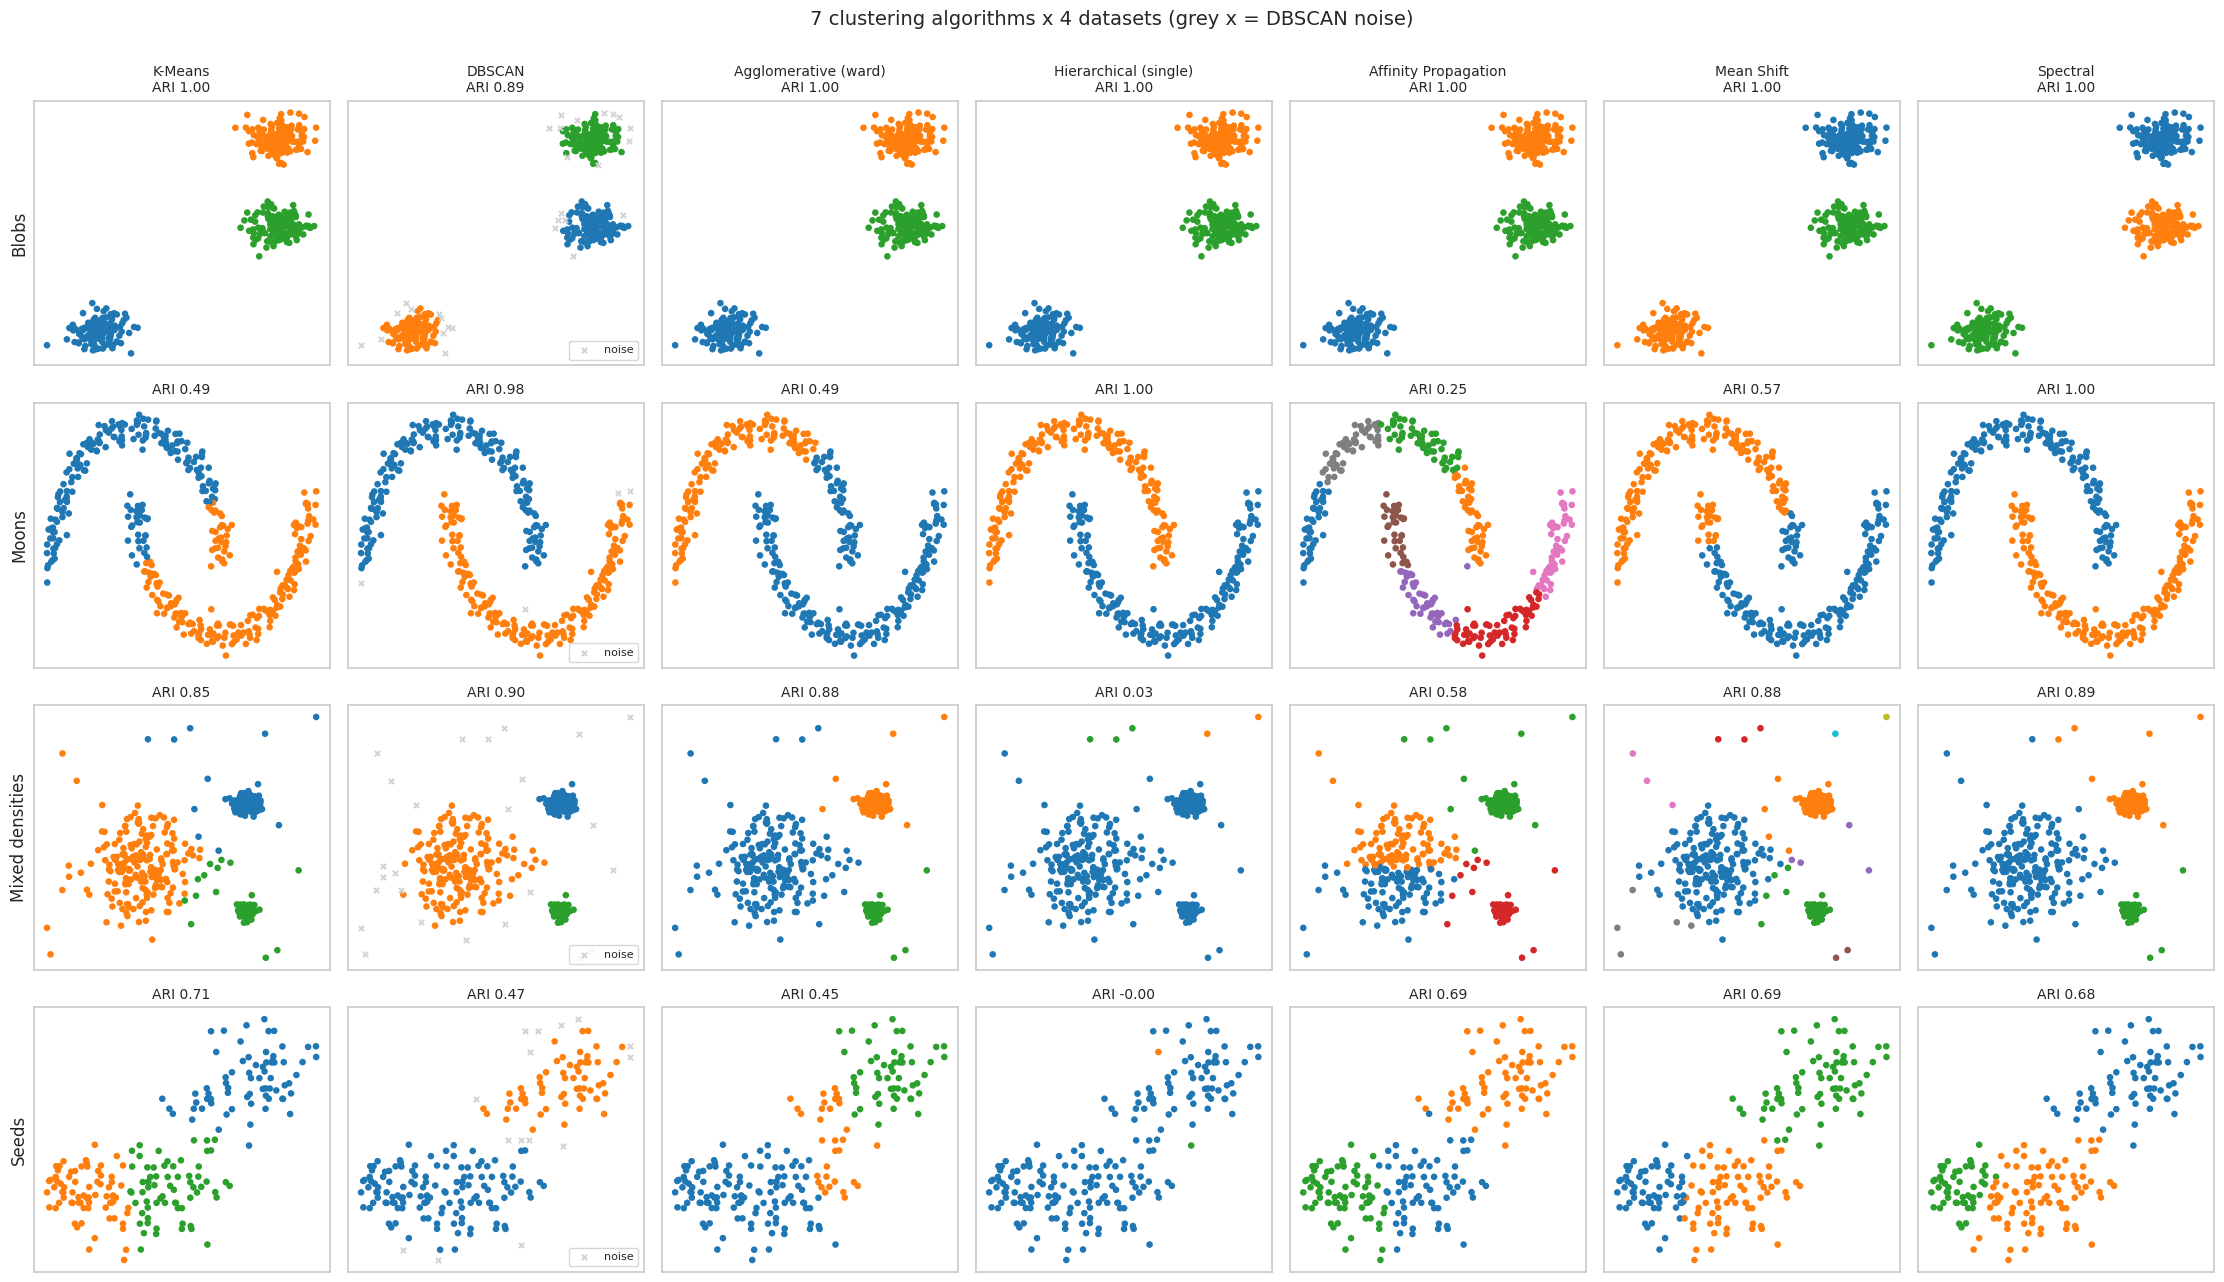

In [23]:
algos = ['K-Means', 'DBSCAN', 'Agglomerative (ward)', 'Hierarchical (single)', 'Affinity Propagation', 'Mean Shift', 'Spectral']
fig, axes = plt.subplots(len(datasets), len(algos), figsize=(3.2 * len(algos), 3.2 * len(datasets)))
for i, dname in enumerate(datasets):
    for j, aname in enumerate(algos):
        Zd, lab = all_labels[(dname, aname)]
        ari = results.query('dataset == @dname and algorithm == @aname')['ARI'].iloc[0]
        ax = axes[i, j]; plot_clusters(Zd, lab, ax, f'ARI {ari:.2f}')
        ax.set_xticks([]); ax.set_yticks([])
        if i == 0: ax.set_title(f'{aname}\nARI {ari:.2f}', fontsize=10)
        if j == 0: ax.set_ylabel(dname, fontsize=12)
plt.suptitle('7 clustering algorithms x 4 datasets (grey x = DBSCAN noise)', y=1.0, fontsize=14)
plt.tight_layout();

### The scorecard

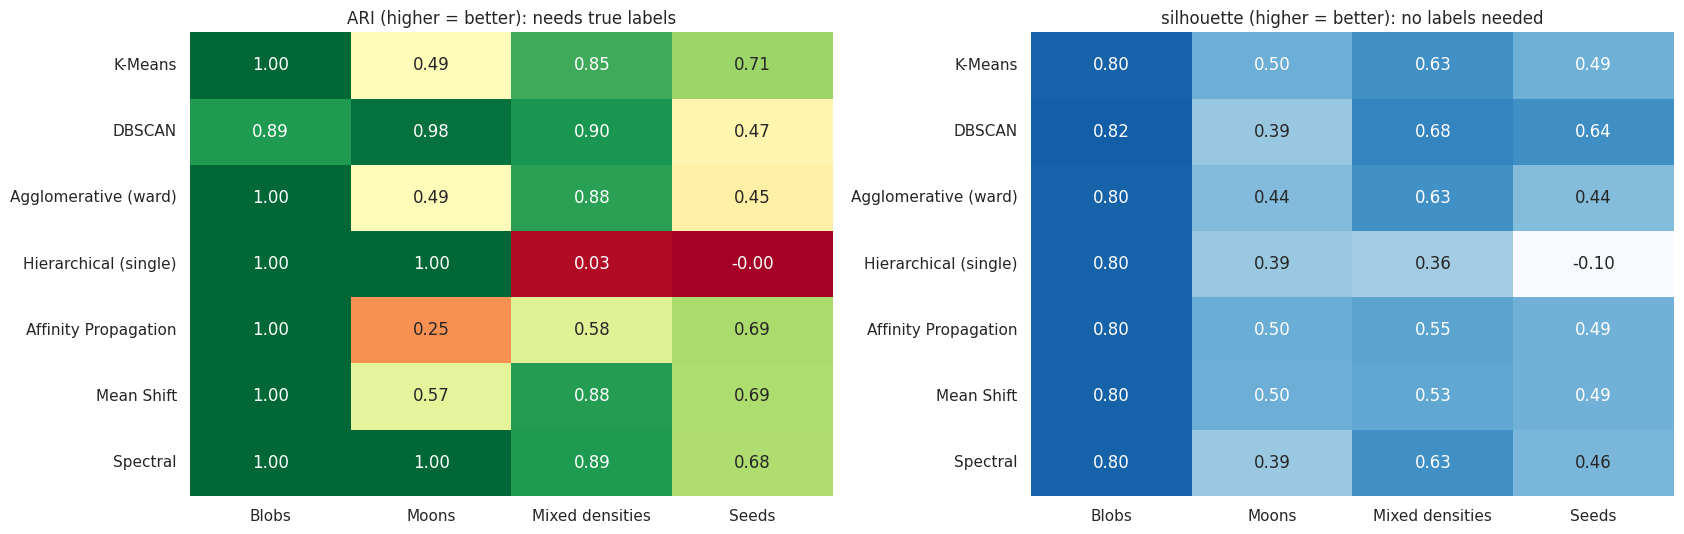

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
for ax, metric, cmap in zip(axes, ['ARI', 'silhouette'], ['RdYlGn', 'Blues']):
    grid = results.pivot(index='algorithm', columns='dataset', values=metric).loc[algos, list(datasets)]
    sns.heatmap(grid, annot=True, fmt='.2f', cmap=cmap, vmin=0, vmax=1, ax=ax, cbar=False)
    ax.set_title(f'{metric} (higher = better)' + (': needs true labels' if metric == 'ARI' else ': no labels needed'))
    ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout();

**Reading the scorecard:**
- **Blobs:** every method does well (DBSCAN labels a few edge points as noise). On easy data the choice hardly matters, so pick the simplest (k-means).
- **Moons:** only the shape-following methods (DBSCAN, single linkage, spectral) get it right. k-means and Ward cut each moon in half.
- **Mixed densities:** DBSCAN does best: it finds all three clusters **and** flags the scattered outliers as noise. Spectral, Mean Shift, Ward and k-means also cope, but they must put every outlier in some cluster. Single linkage collapses (it chains through the outliers), and Affinity Propagation splits the big cluster. (DBSCAN can still struggle when densities differ more; HDBSCAN, below, is built for that.)
- **Seeds:** the overlapping varieties suit the centroid-style methods (k-means, Affinity Propagation, Mean Shift, spectral); density and chaining methods struggle.
- **Silhouette vs ARI:** on the moons, the silhouette scores k-means' wrong answer *higher* than the correct ones. The silhouette rewards round, compact clusters, so it can't be the only judge.

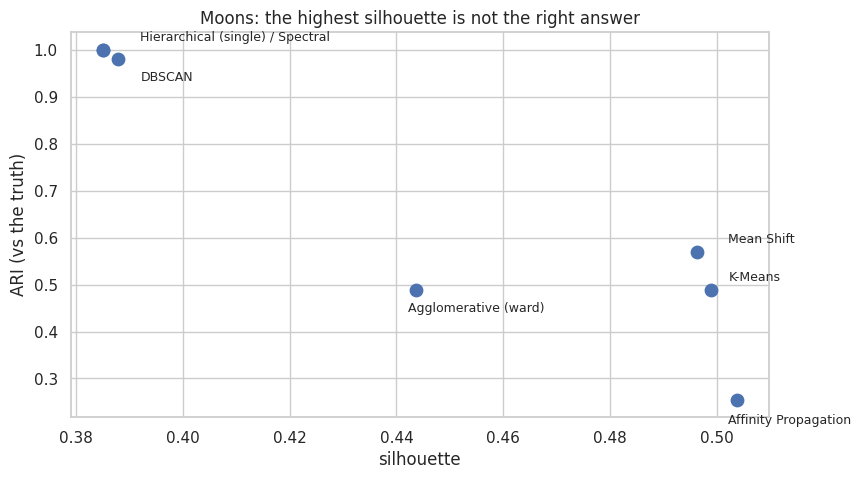

In [25]:
moons = results[results['dataset'] == 'Moons'].set_index('algorithm').loc[algos]
ax = moons.plot.scatter(x='silhouette', y='ARI', s=80, figsize=(9, 5))
groups = moons.groupby([moons['silhouette'].round(2), moons['ARI'].round(2)])     # algorithms that land on the same spot
for i, ((sil, ari), grp) in enumerate(sorted(groups, key=lambda g: -g[0][1])):
    ax.annotate(' / '.join(grp.index), (sil, ari), xytext=(8, 6 if i % 2 == 0 else -16), textcoords='offset points', fontsize=9)
ax.set_title('Moons: the highest silhouette is not the right answer'); ax.set_xlabel('silhouette'); ax.set_ylabel('ARI (vs the truth)');

### How many clusters did each method find, and how long did it take?

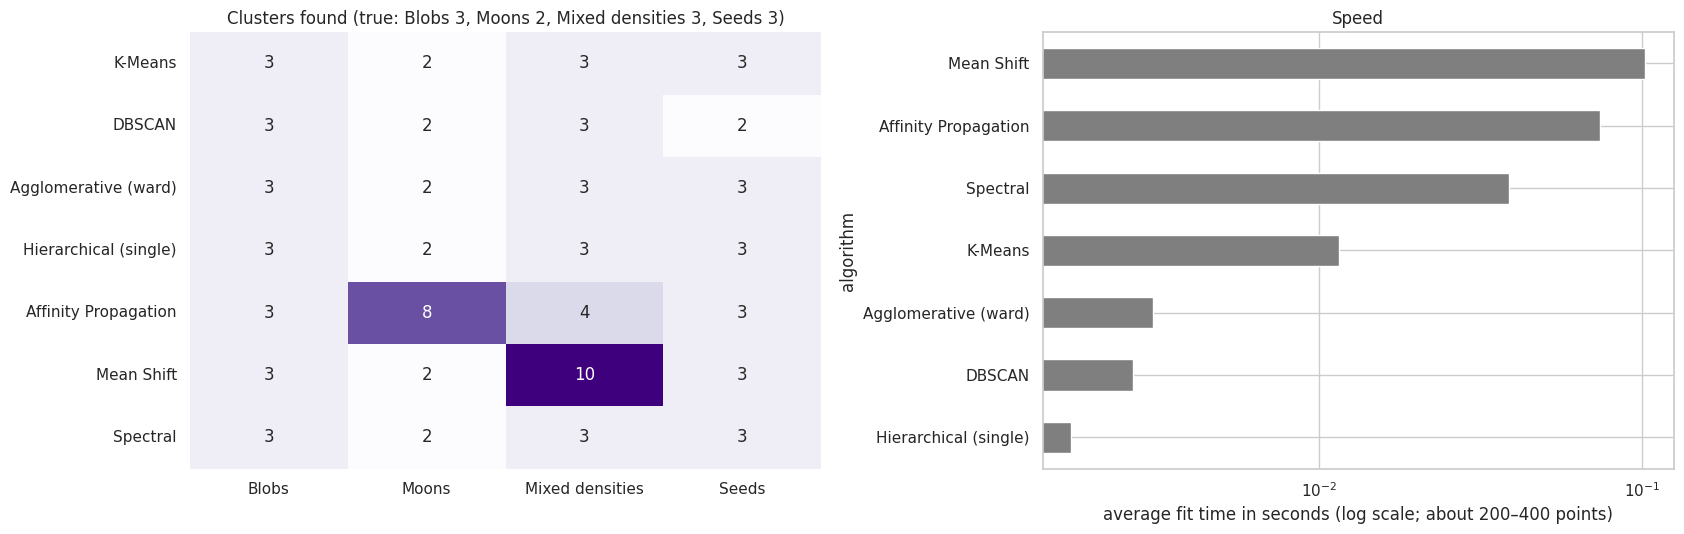

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
found = results.pivot(index='algorithm', columns='dataset', values='clusters found').loc[algos, list(datasets)]
truth = pd.Series({d: k for d, (_, _, k) in datasets.items()})
sns.heatmap(found, annot=True, fmt='d', cmap='Purples', cbar=False, ax=axes[0])
axes[0].set_title('Clusters found (true: ' + ', '.join(f'{d} {k}' for d, k in truth.items()) + ')')
axes[0].set_xlabel(''); axes[0].set_ylabel('')
results.groupby('algorithm')['seconds'].mean().loc[algos].sort_values().plot(kind='barh', ax=axes[1], color='tab:grey', logx=True)
axes[1].set_xlabel('average fit time in seconds (log scale; about 200–400 points)'); axes[1].set_title('Speed')
plt.tight_layout();

The methods that need **k** were given the true number; DBSCAN, Mean Shift and Affinity Propagation had to find it themselves. Mean Shift and Affinity Propagation sometimes find extra small clusters (up to 10), while DBSCAN found too few on the overlapping seeds. Affinity Propagation and Spectral Clustering compare every pair of points, so they slow down sharply on large datasets (thousands of rows and up); k-means and DBSCAN scale much better.

In [27]:
summary = results.groupby('algorithm')[['ARI', 'silhouette', 'seconds']].mean().loc[algos]
summary['datasets with ARI >= 0.8'] = results.assign(good=results['ARI'] >= 0.8).groupby('algorithm')['good'].sum().loc[algos]
summary.sort_values('ARI', ascending=False).round(3)

,ARI,silhouette,seconds,datasets with ARI >= 0.8
algorithm,,,,
Spectral,0.893,0.570,0.039,3
DBSCAN,0.809,0.630,0.003,3
Mean Shift,0.785,0.580,0.102,2
K-Means,0.763,0.606,0.012,2
Agglomerative (ward),0.704,0.577,0.003,2
Affinity Propagation,0.631,0.585,0.074,1
Hierarchical (single),0.506,0.363,0.002,2


### Bonus: HDBSCAN
`HDBSCAN` (scikit-learn 1.3+) is DBSCAN's modern successor: it handles clusters of **different densities** and only needs `min_cluster_size`.

In [28]:
from sklearn.cluster import HDBSCAN
for dname, (Xd, yd, k) in datasets.items():
    lab = HDBSCAN(min_cluster_size=15, copy=True).fit_predict(StandardScaler().fit_transform(Xd))
    print(f'{dname:16s} clusters {len(set(lab) - {-1})} | noise {(lab == -1).mean():5.1%} | ARI {adjusted_rand_score(yd, lab):.2f}')

Blobs            clusters 3 | noise  0.0% | ARI 1.00
Moons            clusters 2 | noise  0.2% | ARI 1.00
Mixed densities  clusters 3 | noise  7.8% | ARI 0.87
Seeds            clusters 2 | noise 16.2% | ARI 0.43


# Part 6: Choosing a clustering algorithm
---
| If your data… | Try first | Why |
|---|---|---|
| has round, similar-sized groups and you know (or can choose) k | **K-Means** | fast, simple, scales to large data |
| has odd shapes and/or outliers to flag | **DBSCAN** / **HDBSCAN** | follows density; finds k; labels noise |
| needs a hierarchy, or a dendrogram to choose k | **Agglomerative** | pick the linkage to suit the shape (ward for blobs, single for chains) |
| has curved shapes and you know k | **Spectral** | follows the neighbour graph; slower on big data |
| should find k by itself, with roughly round groups | **Mean Shift** / **Affinity Propagation** | no k needed, but sensitive to bandwidth / preference, and slow on big data |

**The approach to reuse in your projects:** scale the data; try several algorithms with sensible settings; compare them on a **scorecard** (silhouette, number of clusters, noise share, time, and ARI if you ever have labels); **plot** the results; and let domain knowledge make the final call.

# Conclusions and Takeaways
---
- **DBSCAN** clusters by density: no k needed, any shape, flags outliers, but two settings (use the k-distance plot for `eps`) and one density for all clusters.
- **Agglomerative clustering** merges the closest clusters step by step; the **linkage** decides what "closest" means, and the **dendrogram** shows the whole hierarchy.
- **Affinity Propagation** and **Mean Shift** find k themselves but are sensitive to their settings; **Spectral** follows shapes but needs k.
- **Metrics can mislead:** exclude noise from the silhouette, and remember the silhouette prefers round clusters.
- No algorithm wins everywhere. Match the method to the **shape** of your data, and always look at the clusters.

### Questions
<details><summary>Why did k-means fail on the moons while DBSCAN succeeded?</summary>

k-means assigns points to the nearest centroid, so its clusters are always roughly round regions, and it cuts each curved moon in half. DBSCAN links dense neighbouring points, so it can follow any shape.
</details>

<details><summary>Why should DBSCAN's noise points be excluded from the silhouette score?</summary>

Noise isn't a cluster: its points are scattered by definition. Counting label −1 as a cluster distorts the score and can make a good clustering look bad (or vice versa).
</details>

<details><summary>When would single linkage be a bad choice?</summary>

When clusters touch or the data has outliers: single linkage "chains" clusters together through the closest pair of points (it collapsed on the seeds and mixed-density data).
</details>


## Further reading
- scikit-learn's [clustering overview](https://scikit-learn.org/stable/modules/clustering.html), with its famous comparison chart.
- [Visualizing DBSCAN](https://www.naftaliharris.com/blog/visualizing-dbscan-clustering/), an interactive demo by Naftali Harris.